# Nama: Eko Hadi Prasetiyo
# NIM: 23031554121
# Kelas: 2023B

### Uji Coba

In [ ]:
from neo4j import GraphDatabase, RoutingControl

URI = "bolt://localhost:7687"
AUTH = ("neo4j", "password_anda")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Terhubung!")

Terhubung!


In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

In [4]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Setup Data

In [ ]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(URI, auth=("neo4j", "password_anda"))
session = driver.session(database="system")

In [3]:
import os
import sys

source = r"C:\Users\HP\Videos\UTS GRAF\ecommerce-dataset"
csv_file_path = os.path.join(source, "events.csv")

if not os.path.isfile(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)
else:
    print("File ditemukan:", csv_file_path)

File ditemukan: C:\Users\HP\Videos\UTS GRAF\ecommerce-dataset\events.csv


In [ ]:
from neo4j import GraphDatabase
import sys

bolt = "bolt://localhost:7687"
user = "neo4j"
password = "password_anda"

try:
    driver = GraphDatabase.driver(bolt, auth=(user, password))
    driver.verify_connectivity()
    print("Berhasil terhubung ke database!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

Berhasil terhubung ke database!


In [1]:
import pandas as pd
from tqdm.auto import tqdm

def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorid IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemid IS UNIQUE"
    )

def import_batch(tx, records):
    tx.run(
        """
        UNWIND $records AS row
        MERGE (v:Visitor {visitorid: row.visitorid})
        MERGE (i:Item {itemid: row.itemid})
        FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
            CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i))
        FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
            CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))
        FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
            CREATE (v)-[:PURCHASED {timestamp: row.timestamp,
                                    transactionid: row.transactionid}]->(i))
        """,
        records=records,
    )

In [7]:
batch_size = 5000

# hitung total baris (dikurangi 1 untuk header)
with open(csv_file_path, encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1
total_chunks = -(-total_rows // batch_size)   # pembulatan ke atas

with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size,
        dtype={"transactionid": str},   # cegah "4000.0"
    )

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = chunk["transactionid"].fillna("")
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: C:\Users\HP\Videos\UTS GRAF\ecommerce-dataset\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/552 [00:00<?, ?it/s]

Proses impor berhasil.


### Soal Uts

### 1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama! (akan ditentukan)
Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024

In [8]:
import os
import pandas as pd

events = pd.read_csv(csv_file_path, dtype={"transactionid": str})

waktu = pd.to_datetime(events["timestamp"], unit="ms", utc=True)
print(waktu.min(), "->", waktu.max())

2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00


### 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [ ]:
P1 = ("2015-05-21", "2015-07-21")   # fold training
P2 = ("2015-07-30", "2015-08-14")   # fold testing

def batas(tanggal, akhir=False):
    t = pd.Timestamp(tanggal, tz="UTC")
    if akhir:
        t += pd.Timedelta(days=1)    # tanggal akhir ikut terhitung sampai 23:59:59
    return t.value // 1_000_000      # nanodetik -> milidetik

ts = events["timestamp"]
m1 = (ts >= batas(P1[0])) & (ts < batas(P1[1], akhir=True))
m2 = (ts >= batas(P2[0])) & (ts < batas(P2[1], akhir=True))

filtered = events[m1 | m2].copy()
filtered["periode"] = "P1"
filtered.loc[m2[filtered.index], "periode"] = "P2"

print("Baris P1 (training):", m1.sum())
print("Baris P2 (testing) :", m2.sum())
print("Total tersimpan    :", len(filtered))

out_path = os.path.join(os.path.dirname(csv_file_path), "events_filtered.csv")
filtered.to_csv(out_path, index=False)
print("Disimpan ke:", out_path)

Baris P1 (training): 1286441
Baris P2 (testing) : 292002
Total tersimpan    : 1578443
Disimpan ke: C:\Users\HP\Videos\UTS GRAF\ecommerce-dataset\events_filtered.csv


### 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [ ]:
from neo4j import GraphDatabase
import pandas as pd

driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", "password_anda"))

# 1. Jenis simpul dan jumlahnya
q_node = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
records, _, _ = driver.execute_query(q_node, database_="neo4j")
df_node = pd.DataFrame([r.data() for r in records])
print("Komposisi simpul:")
print(df_node.to_string(index=False))
print("Total simpul:", df_node["jumlah"].sum())

# 2. Jenis relasi dan jumlahnya (pelengkap)
q_rel = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
records, _, _ = driver.execute_query(q_rel, database_="neo4j")
df_rel = pd.DataFrame([r.data() for r in records])
print("\nKomposisi relasi:")
print(df_rel.to_string(index=False))
print("Total relasi:", df_rel["jumlah"].sum())

driver.close()

Komposisi simpul:
jenis_simpul  jumlah
     Visitor 1407580
        Item  235061
Total simpul: 1642641

Komposisi relasi:
 jenis_relasi  jumlah
       VIEWED 2664312
ADDED_TO_CART   69332
    PURCHASED   22457
Total relasi: 2756101


1. Query simpul

MATCH (n)

RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah

ORDER BY jumlah DESC




MATCH (n): Mencocokkan semua simpul di database. n adalah variabel penampung. Tanpa label, simpul jenis apa pun ikut terambil.

labels(n): Fungsi yang mengembalikan daftar label simpul n, misalnya ["Visitor"].

[0]: Mengambil elemen pertama daftar itu. Aman karena tiap simpul di model ini hanya punya satu label.

count(n): Fungsi agregasi yang menghitung jumlah simpul.

AS jenis_simpul: Memberi nama kolom hasil (alias).

ORDER BY jumlah DESC: Mengurutkan dari jumlah terbesar ke terkecil.




2. Query relasi

MATCH ()-[r]->()

RETURN type(r) AS jenis_relasi, count(r) AS jumlah

ORDER BY jumlah DESC





()-[r]->() adalah pola relasi berarah. Simpul di kiri dan kanan tidak diberi nama karena tidak dipakai, sedangkan r menampung relasinya.

type(r) mengembalikan nama jenis relasi (VIEWED, ADDED_TO_CART, PURCHASED).


### 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [ ]:
from neo4j import GraphDatabase
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", "password_anda"))

q = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|PURCHASED]->(i:Item)
RETURN v.visitorid AS visitorid, i.itemid AS itemid,
       type(r) AS jenis, count(r) AS n
"""
records, _, _ = driver.execute_query(q, database_="neo4j")
df = pd.DataFrame([r.data() for r in records])
driver.close()
print(df.shape)
df.head()

(2215422, 4)


,visitorid,itemid,jenis,n
0,257597,355908,VIEWED,1
1,981382,355908,VIEWED,1
2,1102250,355908,VIEWED,1
3,62710,355908,VIEWED,1
4,76757,355908,VIEWED,1


In [12]:
# Bobot per jenis interaksi (bisa diubah sesuai kebutuhan tugas)
W = {"VIEWED": 1, "ADDED_TO_CART": 2, "PURCHASED": 3}
df["bobot"] = df["jenis"].map(W) * df["n"]
pairs = df.groupby(["visitorid", "itemid"], as_index=False)["bobot"].sum()

user_ids = pairs["visitorid"].unique()
item_ids = pairs["itemid"].unique()
u_idx = {u: k for k, u in enumerate(user_ids)}
i_idx = {i: k for k, i in enumerate(item_ids)}

X = csr_matrix(
    (pairs["bobot"], (pairs["visitorid"].map(u_idx), pairs["itemid"].map(i_idx))),
    shape=(len(user_ids), len(item_ids)),
)

n_user, n_item = X.shape
nnz = X.nnz
per_user = X.getnnz(axis=1)          # jumlah item berbeda per user
norm = np.sqrt(X.multiply(X).sum(axis=1)).A1   # panjang vektor tiap user

print("Shape matriks        :", X.shape)
print("Jumlah vektor (user) :", n_user)
print("Dimensi (item unik)  :", n_item)
print("Elemen non-nol       :", nnz)
print("Sparsity             : {:.6f} ({:.4f}% sel kosong)".format(
    1 - nnz / (n_user * n_item), 100 * (1 - nnz / (n_user * n_item))))
print("Rata-rata item/user  :", per_user.mean())
print("Median item/user     :", np.median(per_user))
print("Maks item/user       :", per_user.max())
print("Rata-rata norma      :", norm.mean())

Shape matriks        : (1407580, 235061)
Jumlah vektor (user) : 1407580
Dimensi (item unik)  : 235061
Elemen non-nol       : 2145179
Sparsity             : 0.999994 (99.9994% sel kosong)
Rata-rata item/user  : 1.5240192386933602
Median item/user     : 1.0
Maks item/user       : 3814
Rata-rata norma      : 1.5052999246694392


Simpul: 30 | Sisi: 139


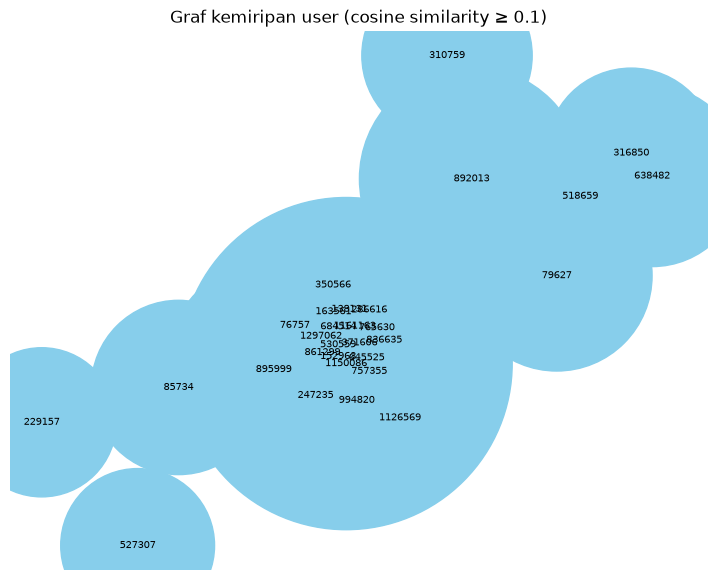

In [13]:
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import diags

# Normalisasi baris agar perkalian matriks = cosine similarity
Xn = diags(1 / np.where(norm == 0, 1, norm)) @ X

# Ambil 30 user paling aktif sebagai sampel
top = np.argsort(-per_user)[:30]
S = (Xn[top] @ Xn[top].T).toarray()
np.fill_diagonal(S, 0)

THRESHOLD = 0.1   # turunkan jika graf kosong
G = nx.Graph()
for a in range(len(top)):
    G.add_node(user_ids[top[a]], aktivitas=per_user[top[a]])
    for b in range(a + 1, len(top)):
        if S[a, b] >= THRESHOLD:
            G.add_edge(user_ids[top[a]], user_ids[top[b]], weight=S[a, b])

print("Simpul:", G.number_of_nodes(), "| Sisi:", G.number_of_edges())

pos = nx.spring_layout(G, seed=42)
ukuran = [G.nodes[n]["aktivitas"] * 15 for n in G.nodes]
lebar = [G[u][v]["weight"] * 4 for u, v in G.edges]

plt.figure(figsize=(9, 7))
nx.draw_networkx(G, pos, node_size=ukuran, width=lebar,
                 node_color="skyblue", edge_color="gray", font_size=7)
plt.title("Graf kemiripan user (cosine similarity ≥ {})".format(THRESHOLD))
plt.axis("off")
plt.show()

### 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [14]:
import numpy as np

Xi = X.T.tocsr()          # baris = item, kolom = user

n_item, n_user = Xi.shape
nnz = Xi.nnz
per_item = Xi.getnnz(axis=1)                    # jumlah user berbeda per item
norm_i = np.sqrt(Xi.multiply(Xi).sum(axis=1)).A1
total_bobot = Xi.sum(axis=1).A1                 # total bobot interaksi per item

print("Shape matriks        :", Xi.shape)
print("Jumlah vektor (item) :", n_item)
print("Dimensi (user unik)  :", n_user)
print("Elemen non-nol       :", nnz)
print("Sparsity             : {:.6f} ({:.4f}% sel kosong)".format(
    1 - nnz / (n_item * n_user), 100 * (1 - nnz / (n_item * n_user))))
print("Rata-rata user/item  :", per_item.mean())
print("Median user/item     :", np.median(per_item))
print("Maks user/item       :", per_item.max())
print("Item hanya 1 user    :", (per_item == 1).sum())
print("Rata-rata norma      :", norm_i.mean())

Shape matriks        : (235061, 1407580)
Jumlah vektor (item) : 235061
Dimensi (user unik)  : 1407580
Elemen non-nol       : 2145179
Sparsity             : 0.999994 (99.9994% sel kosong)
Rata-rata user/item  : 9.126052386401827
Median user/item     : 2.0
Maks user/item       : 2912
Item hanya 1 user    : 81347
Rata-rata norma      : 3.3619211338660047


Simpul: 30 | Sisi: 14


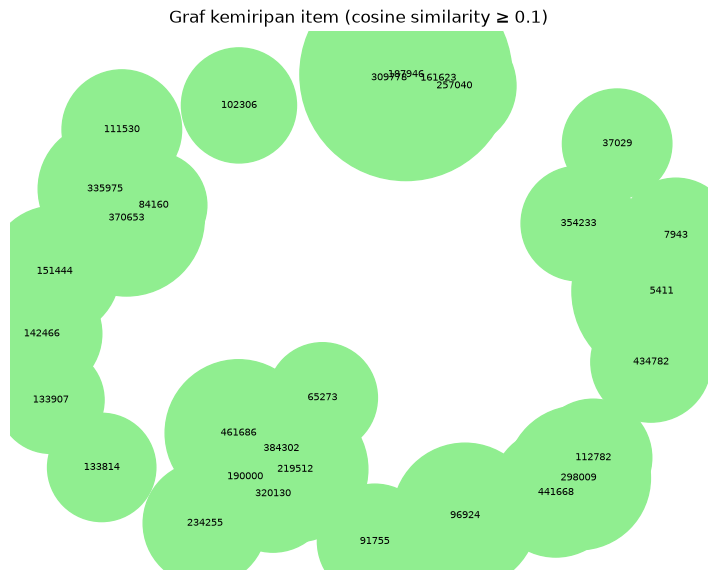

In [15]:
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import diags

# Normalisasi baris agar perkalian matriks = cosine similarity
Xin = diags(1 / np.where(norm_i == 0, 1, norm_i)) @ Xi

# Ambil 30 item paling populer sebagai sampel
top = np.argsort(-per_item)[:30]
S = (Xin[top] @ Xin[top].T).toarray()
np.fill_diagonal(S, 0)

THRESHOLD = 0.1   # turunkan jika graf kosong
G = nx.Graph()
for a in range(len(top)):
    G.add_node(item_ids[top[a]], populer=per_item[top[a]])
    for b in range(a + 1, len(top)):
        if S[a, b] >= THRESHOLD:
            G.add_edge(item_ids[top[a]], item_ids[top[b]], weight=S[a, b])

print("Simpul:", G.number_of_nodes(), "| Sisi:", G.number_of_edges())

pos = nx.spring_layout(G, seed=42)
ukuran = [G.nodes[n]["populer"] * 8 for n in G.nodes]
lebar = [G[u][v]["weight"] * 4 for u, v in G.edges]

plt.figure(figsize=(9, 7))
nx.draw_networkx(G, pos, node_size=ukuran, width=lebar,
                 node_color="lightgreen", edge_color="gray", font_size=7)
plt.title("Graf kemiripan item (cosine similarity ≥ {})".format(THRESHOLD))
plt.axis("off")
plt.show()

### 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Proyeksi item lebih efisien dan lebih efektif. Jumlah vektor item (235.061) jauh lebih sedikit daripada user (1.407.580), sehingga pasangan yang dibandingkan turun sekitar 36 kali. Vektor item juga lebih padat (rata-rata 9,13 vs 1,52 interaksi; median 2 vs 1) dengan proporsi vektor beranggota tunggal yang lebih kecil (34,6% vs minimal 50%). Graf sampel item lebih jarang karena sampel top-30 user bersifat ekstrem dan tidak representatif.

### 7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

In [ ]:
from neo4j import GraphDatabase
import pandas as pd
import numpy as np

driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", "password_anda"))

rec, _, _ = driver.execute_query(
    """
    MATCH (i:Item)<--(v:Visitor)
    RETURN i.itemid AS itemid, count(DISTINCT v) AS pengunjung
    ORDER BY pengunjung DESC LIMIT 1
    """,
    database_="neo4j",
)
ACUAN = rec[0]["itemid"]
print("Item acuan:", ACUAN, "| jumlah pengunjung:", rec[0]["pengunjung"])

Item acuan: 187946 | jumlah pengunjung: 2912


## (a) Cypher: 5 item dengan similarity tertinggi

In [17]:
BASE = """
MATCH (a:Item {itemid: $acuan})<--(v:Visitor)
WITH a, collect(DISTINCT v) AS users
WITH a, users, size(users) AS na
UNWIND users AS u
MATCH (u)-->(b:Item)
WHERE b <> a
WITH a, na, b, count(DISTINCT u) AS bersama
MATCH (b)<--(vb:Visitor)
WITH a, na, b, bersama, count(DISTINCT vb) AS nb
WITH a, b, na, nb, bersama,
     toFloat(bersama) / (na + nb - bersama)      AS jaccard,
     toFloat(bersama) / sqrt(toFloat(na) * nb)   AS cosine
ORDER BY jaccard DESC, bersama DESC
LIMIT 5
"""

Q_A = BASE + """
RETURN a.itemid AS acuan, b.itemid AS item_mirip,
       na AS user_acuan, nb AS user_item_mirip, bersama,
       round(jaccard, 4) AS jaccard, round(cosine, 4) AS cosine
"""

rec, _, _ = driver.execute_query(Q_A, acuan=ACUAN, database_="neo4j")
df_a = pd.DataFrame([r.data() for r in rec])
print(df_a.to_string(index=False))

 acuan  item_mirip  user_acuan  user_item_mirip  bersama  jaccard  cosine
187946      133549        2912               70       14   0.0047  0.0310
187946      181852        2912               44        7   0.0024  0.0196
187946      101050        2912               76        6   0.0020  0.0128
187946      384528        2912               34        5   0.0017  0.0159
187946       36956        2912               29        4   0.0014  0.0138


## (b) Menulis nilai similarity kembali ke graf

In [18]:
Q_B = BASE + """
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.jaccard = jaccard, s.cosine = cosine, s.bersama = bersama
RETURN count(s) AS relasi_ditulis
"""
rec, _, _ = driver.execute_query(Q_B, acuan=ACUAN, database_="neo4j")
print("Relasi SIMILAR_TO ditulis/diperbarui:", rec[0]["relasi_ditulis"])

Relasi SIMILAR_TO ditulis/diperbarui: 5


In [19]:
Q_CEK = """
MATCH (a:Item {itemid: $acuan})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemid AS acuan, b.itemid AS item_mirip, s.bersama AS bersama,
       round(s.jaccard, 4) AS jaccard, round(s.cosine, 4) AS cosine
ORDER BY s.jaccard DESC
"""
rec, _, _ = driver.execute_query(Q_CEK, acuan=ACUAN, database_="neo4j")
print(pd.DataFrame([r.data() for r in rec]).to_string(index=False))

rec, _, _ = driver.execute_query(
    "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS total", database_="neo4j")
print("Total relasi SIMILAR_TO di graf:", rec[0]["total"])

 acuan  item_mirip  bersama  jaccard  cosine
187946      133549       14   0.0047  0.0310
187946      181852        7   0.0024  0.0196
187946      101050        6   0.0020  0.0128
187946      384528        5   0.0017  0.0159
187946       36956        4   0.0014  0.0138
Total relasi SIMILAR_TO di graf: 5


### 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [ ]:
# Sel 1: hapus SIMILAR_TO dan catat komposisi relasi
def komposisi(label):
    rec, _, _ = driver.execute_query(
        "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah "
        "ORDER BY jumlah DESC", database_="neo4j")
    df = pd.DataFrame([r.data() for r in rec])
    print(label)
    print(df.to_string(index=False), "\n")
    return df

# Hapus hasil perhitungan sebelumnya (hanya relasi SIMILAR_TO)
driver.execute_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s", database_="neo4j")

df_before = komposisi("=== SEBELUM similarity ===")

=== SEBELUM similarity ===
 jenis_relasi  jumlah
       VIEWED 2664312
ADDED_TO_CART   69332
    PURCHASED   22457 



In [23]:
# Sel 2: cetak query visual “sebelum”
tetangga = df_a["item_mirip"].tolist()

q_before = f"""MATCH (a:Item {{itemid: {ACUAN}}})
MATCH (b:Item) WHERE b.itemid IN {tetangga}
MATCH q = (a)<--(v:Visitor)-->(b)
WITH a, b, collect(q)[..3] AS qs
UNWIND qs AS q
RETURN q"""
print(q_before)

MATCH (a:Item {itemid: 187946})
MATCH (b:Item) WHERE b.itemid IN [133549, 181852, 101050, 384528, 36956]
MATCH q = (a)<--(v:Visitor)-->(b)
WITH a, b, collect(q)[..3] AS qs
UNWIND qs AS q
RETURN q


In [24]:
# Sel 3: jalankan perhitungan dan penulisan (sama seperti bagian (b) sebelumnya)
rec, _, _ = driver.execute_query(Q_B, acuan=ACUAN, database_="neo4j")
print("Relasi SIMILAR_TO ditulis:", rec[0]["relasi_ditulis"])


Relasi SIMILAR_TO ditulis: 5


In [25]:
#Sel 4: komposisi relasi dan tabel similarity
df_after = komposisi("=== SESUDAH similarity ===")

rec, _, _ = driver.execute_query("""
    MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item)
    RETURN a.itemid AS acuan, b.itemid AS item_mirip, s.bersama AS bersama,
           round(s.jaccard, 4) AS jaccard, round(s.cosine, 4) AS cosine
    ORDER BY s.jaccard DESC""", database_="neo4j")
print(pd.DataFrame([r.data() for r in rec]).to_string(index=False))

=== SESUDAH similarity ===
 jenis_relasi  jumlah
       VIEWED 2664312
ADDED_TO_CART   69332
    PURCHASED   22457
   SIMILAR_TO       5 

 acuan  item_mirip  bersama  jaccard  cosine
187946      133549       14   0.0047  0.0310
187946      181852        7   0.0024  0.0196
187946      101050        6   0.0020  0.0128
187946      384528        5   0.0017  0.0159
187946       36956        4   0.0014  0.0138


### 2.2 Analytics

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [26]:
# Parameter dan Persiapan
import numpy as np
import pandas as pd
from scipy.sparse import diags

SEED  = 42    # tetapkan satu angka dan tulis di laporan (mis. 4 digit terakhir NIM)
K     = 5     # jumlah tetangga terdekat
N_REK = 3     # jumlah item yang diiklankan

user_ids = np.asarray(user_ids)
item_ids = np.asarray(item_ids)

# Normalisasi baris user, sehingga perkalian titik = cosine similarity
norm_u = np.sqrt(X.multiply(X).sum(axis=1)).A1
Xn = (diags(1 / np.where(norm_u == 0, 1, norm_u)) @ X).tocsr()
per_user = X.getnnz(axis=1)

In [27]:
# Fungsi rekomendasi KNN
def knn_rekomendasi(u, k=K, n_rek=N_REK):
    # 1. Cosine similarity user u terhadap semua user
    sim = (Xn @ Xn[u].T).toarray().ravel()
    sim[u] = 0                                    # buang diri sendiri

    # 2. k tetangga terdekat (seri diputus dengan visitorid agar reprodusibel)
    urut = np.lexsort((user_ids, -sim))[:k]
    urut = urut[sim[urut] > 0]
    w = sim[urut]
    if len(urut) == 0:
        return None

    # 3. Skor item = jumlah (similarity tetangga x bobot interaksi tetangga)
    skor = np.asarray(X[urut].T @ w).ravel()
    skor[X[u].indices] = 0                        # buang item yang sudah pernah disentuh user

    # 4. Top-N item (seri diputus dengan itemid)
    top = np.lexsort((item_ids, -skor))[:n_rek]
    top = top[skor[top] > 0]

    # Ringkasan untuk pelaporan
    Bn = (X[urut] > 0).astype(int)
    bu = (X[u] > 0).astype(int)
    item_sama = (Bn @ bu.T).toarray().ravel()
    dukungan = np.asarray(Bn.sum(axis=0)).ravel()

    return {
        "tetangga": pd.DataFrame({"visitorid": user_ids[urut],
                                  "similarity": w.round(4),
                                  "item_sama": item_sama}),
        "rekomendasi": pd.DataFrame({"itemid": item_ids[top],
                                     "skor": skor[top].round(4),
                                     "didukung_tetangga": dukungan[top]}),
    }

In [28]:
# Pemilihan user acak
rng = np.random.default_rng(SEED)

# Kandidat: user dengan minimal 3 item berbeda, diurutkan berdasarkan visitorid
kandidat = np.sort(user_ids[per_user >= 3])
acak = rng.permutation(kandidat)                  # urutan acak, sama untuk seed yang sama

for percobaan, vid in enumerate(acak[:200], 1):
    u = u_idx[vid]
    hasil = knn_rekomendasi(u)
    if (hasil is not None and len(hasil["tetangga"]) == K
            and len(hasil["rekomendasi"]) == N_REK):
        break
else:
    raise RuntimeError("Tidak ada user yang memenuhi syarat dalam 200 percobaan")

print(f"Seed {SEED} | user terpilih: {vid} (percobaan ke-{percobaan})")

print("\nRiwayat interaksi user (bobot: view=1, addtocart=2, purchase=3):")
riw = X[u]
print(pd.DataFrame({"itemid": item_ids[riw.indices], "bobot": riw.data}).to_string(index=False))

print(f"\n{K} tetangga terdekat:")
print(hasil["tetangga"].to_string(index=False))

print(f"\n{N_REK} item yang diiklankan (k = {K}):")
print(hasil["rekomendasi"].to_string(index=False))

Seed 42 | user terpilih: 1031657 (percobaan ke-26)

Riwayat interaksi user (bobot: view=1, addtocart=2, purchase=3):
 itemid  bobot
 275150      1
 397020      1
 118754      1

5 tetangga terdekat:
 visitorid  similarity  item_sama
   1045205      0.7516          2
     14445      0.5774          1
     22004      0.5774          1
    181526      0.5774          1
    190002      0.5774          1

3 item yang diiklankan (k = 5):
 itemid   skor  didukung_tetangga
 351143 3.0065                  1
  41988 2.2549                  1
  21790 1.5033                  1


### 2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
(a) Hit@5
(b) NDCG@5

In [ ]:
# pisahkan P1 (training) dan P2 (testing)
import os
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, diags

UID  = 1031657
SEED = 42
K    = 5
TOPN = 5

# Samakan dengan periode yang kamu pakai pada tahap persiapan data (soal filter timestamp)
P1 = ("2015-05-21", "2015-07-21")   # fold training
P2 = ("2015-07-30", "2015-08-14")   # fold testing

def batas(tanggal, akhir=False):
    t = pd.Timestamp(tanggal, tz="UTC")
    if akhir:
        t += pd.Timedelta(days=1)
    return t.value // 1_000_000

folder = os.path.dirname(csv_file_path)
path = os.path.join(folder, "events_filtered.csv")
if not os.path.isfile(path):
    path = os.path.join(folder, "events.csv")

ev = pd.read_csv(path, usecols=["timestamp", "visitorid", "itemid", "event"])
ts = ev["timestamp"]
train = ev[(ts >= batas(P1[0])) & (ts < batas(P1[1], akhir=True))]
test  = ev[(ts >= batas(P2[0])) & (ts < batas(P2[1], akhir=True))]
print("Baris P1:", len(train), "| Baris P2:", len(test))

# Matriks user-item dari P1 saja
W = {"view": 1, "addtocart": 2, "transaction": 3}
tr = (train.assign(bobot=train["event"].map(W))
           .groupby(["visitorid", "itemid"], as_index=False)["bobot"].sum())

uids = np.sort(tr["visitorid"].unique())
iids = np.sort(tr["itemid"].unique())
u_map = {u: k for k, u in enumerate(uids)}
i_map = {i: k for k, i in enumerate(iids)}

Xt = csr_matrix((tr["bobot"], (tr["visitorid"].map(u_map), tr["itemid"].map(i_map))),
                shape=(len(uids), len(iids)))
norm = np.sqrt(Xt.multiply(Xt).sum(axis=1)).A1
Xtn = (diags(1 / np.where(norm == 0, 1, norm)) @ Xt).tocsr()
print("Matriks training:", Xt.shape)

Baris P1: 1286441 | Baris P2: 292002
Matriks training: (663845, 169690)


In [30]:
# fungsi KNN dan metrik
def knn_top_n(u, k=K, n=TOPN):
    sim = (Xtn @ Xtn[u].T).toarray().ravel()
    sim[u] = 0
    urut = np.lexsort((uids, -sim))[:k]
    urut = urut[sim[urut] > 0]
    if len(urut) == 0:
        return np.array([]), np.array([])
    skor = np.asarray(Xt[urut].T @ sim[urut]).ravel()
    skor[Xt[u].indices] = 0
    top = np.lexsort((iids, -skor))[:n]
    top = top[skor[top] > 0]
    return iids[top], skor[top]

def hit_at_k(rek, relevan, k=5):
    return int(any(i in relevan for i in rek[:k]))

def ndcg_at_k(rek, relevan, k=5):
    dcg  = sum(1 / np.log2(r + 2) for r, i in enumerate(rek[:k]) if i in relevan)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(relevan), k)))
    return dcg / idcg if idcg > 0 else 0.0

In [31]:
# evaluasi untuk user 1031657
if UID not in u_map:
    print(f"User {UID} tidak punya interaksi di P1 (cold start), tidak bisa direkomendasikan.")
else:
    u = u_map[UID]
    rek, skor = knn_top_n(u)

    item_p1  = set(train.loc[train["visitorid"] == UID, "itemid"])
    item_p2  = set(test.loc[test["visitorid"] == UID, "itemid"])
    relevan  = item_p2 - item_p1          # item baru di P2 (tidak dihitung yang sudah dilihat di P1)

    print("Item user di P1 :", sorted(item_p1))
    print("Item user di P2 :", sorted(item_p2))
    print("Item relevan    :", sorted(relevan))
    print()
    tabel = pd.DataFrame({
        "peringkat": range(1, len(rek) + 1),
        "itemid": rek,
        "skor": skor.round(4),
        "relevan": ["ya" if i in relevan else "tidak" for i in rek],
        "gain": [round(1 / np.log2(r + 2), 4) if i in relevan else 0 for r, i in enumerate(rek)],
    })
    print(tabel.to_string(index=False))

    if len(relevan) == 0:
        print("\nHit@5 dan NDCG@5 tidak terdefinisi: user tidak punya item baru di P2.")
    else:
        print(f"\nHit@5  = {hit_at_k(rek, relevan)}")
        print(f"NDCG@5 = {ndcg_at_k(rek, relevan):.4f}")

Item user di P1 : [118754, 275150, 397020]
Item user di P2 : []
Item relevan    : []

Empty DataFrame
Columns: [peringkat, itemid, skor, relevan, gain]
Index: []

Hit@5 dan NDCG@5 tidak terdefinisi: user tidak punya item baru di P2.


## Evaluasi


In [32]:
u = u_map[UID]
sim = (Xtn @ Xtn[u].T).toarray().ravel()
sim[u] = 0
print("User lain dengan similarity > 0 di P1:", int((sim > 0).sum()))

urut = np.lexsort((uids, -sim))[:K]
for v in urut[sim[urut] > 0]:
    print(uids[v], round(sim[v], 4), "item:", sorted(iids[Xt[v].indices]))

User lain dengan similarity > 0 di P1: 35
211739 0.5774 item: [np.int64(275150)]
257982 0.5774 item: [np.int64(397020)]
426703 0.5774 item: [np.int64(118754)]
712717 0.5774 item: [np.int64(275150)]
1254219 0.5774 item: [np.int64(275150)]


In [33]:
tr_dict  = train.groupby("visitorid")["itemid"].agg(set).to_dict()
tst_dict = test.groupby("visitorid")["itemid"].agg(set).to_dict()
per_user_tr = Xt.getnnz(axis=1)

kandidat = np.sort([v for v in uids[per_user_tr >= 3]
                    if len(tst_dict.get(v, set()) - tr_dict.get(v, set())) > 0])
print("Kandidat evaluasi:", len(kandidat))

rng = np.random.default_rng(SEED)
for percobaan, vid in enumerate(rng.permutation(kandidat)[:200], 1):
    rek, skor = knn_top_n(u_map[vid])
    if len(rek) > 0:
        break
else:
    raise RuntimeError("Tidak ada kandidat dengan rekomendasi dalam 200 percobaan")

relevan = tst_dict[vid] - tr_dict.get(vid, set())
print(f"\nSeed {SEED} | user evaluasi: {vid} (percobaan ke-{percobaan})")
print("Item di P1   :", sorted(tr_dict[vid]))
print("Item relevan :", sorted(relevan), "(item baru di P2)\n")

tabel = pd.DataFrame({
    "peringkat": range(1, len(rek) + 1),
    "itemid": rek,
    "skor": skor.round(4),
    "relevan": ["ya" if i in relevan else "tidak" for i in rek],
    "gain": [round(1 / np.log2(r + 2), 4) if i in relevan else 0 for r, i in enumerate(rek)],
})
print(tabel.to_string(index=False))
print(f"\nHit@5  = {hit_at_k(rek, relevan)}")
print(f"NDCG@5 = {ndcg_at_k(rek, relevan):.4f}")

Kandidat evaluasi: 2329

Seed 42 | user evaluasi: 823367 (percobaan ke-6)
Item di P1   : [5470, 16673, 22521, 37471, 99257, 100990, 110379, 120541, 135900, 147005, 188759, 199369, 225027, 225257, 230605, 279976, 283110, 287586, 309403, 319999, 335748, 359990, 382751, 452852]
Item relevan : [257040] (item baru di P2)

 peringkat  itemid   skor relevan  gain
         1  414410 0.9282   tidak     0
         2  309778 0.9013   tidak     0
         3  248327 0.8743   tidak     0
         4  209155 0.4641   tidak     0
         5  176106 0.4372   tidak     0

Hit@5  = 0
NDCG@5 = 0.0000


In [34]:
from tqdm.auto import tqdm

MIN_ITEM = 3     # sama dengan aturan kandidat di sel 2 (ubah ke 1 untuk semua user)
N_SAMPEL = 100

tr_dict  = train.groupby("visitorid")["itemid"].agg(set).to_dict()
tst_dict = test.groupby("visitorid")["itemid"].agg(set).to_dict()
per_user_tr = Xt.getnnz(axis=1)

kandidat = np.sort([v for v in uids[per_user_tr >= MIN_ITEM]
                    if len(tst_dict.get(v, set()) - tr_dict.get(v, set())) > 0])
print("User yang bisa dievaluasi:", len(kandidat))

rng = np.random.default_rng(SEED)
sampel = rng.choice(kandidat, size=min(N_SAMPEL, len(kandidat)), replace=False)

hits, ndcgs, punya_rek = [], [], 0
for v in tqdm(sampel, desc="Evaluasi user"):
    rek, _ = knn_top_n(u_map[v])
    rel = tst_dict[v] - tr_dict.get(v, set())
    hits.append(hit_at_k(rek, rel))
    ndcgs.append(ndcg_at_k(rek, rel))
    punya_rek += int(len(rek) > 0)

print(f"\nJumlah user dievaluasi     : {len(sampel)}")
print(f"User yang mendapat rekomendasi: {punya_rek} ({punya_rek / len(sampel) * 100:.1f}%)")
print(f"HitRate@5                  : {np.mean(hits):.4f}  ({sum(hits)} dari {len(sampel)} user)")
print(f"Mean NDCG@5                : {np.mean(ndcgs):.4f}")

User yang bisa dievaluasi: 2329


Evaluasi user:   0%|          | 0/100 [00:00<?, ?it/s]


Jumlah user dievaluasi     : 100
User yang mendapat rekomendasi: 35 (35.0%)
HitRate@5                  : 0.0100  (1 dari 100 user)
Mean NDCG@5                : 0.0017


Evaluasi dilakukan dengan membagi data menjadi fold training (P1) dan fold testing (P2). Lima item teratas direkomendasikan dengan KNN user-based (k = 5, cosine similarity) menggunakan data P1 saja, lalu dicocokkan dengan item baru yang disentuh user di P2 sebagai item relevan. User dari no. 1b (1031657) tidak dapat dievaluasi karena tidak memiliki interaksi di P2 dan tidak menerima rekomendasi dari data P1, sehingga Hit@5 dan NDCG@5 untuk user tersebut tidak terdefinisi, bukan bernilai 0. Evaluasi karena itu dilakukan pada user 823367, yang dipilih ulang dengan proses acak reprodusibel (seed 42) dari 2.329 kandidat (minimal 3 item di P1 dan minimal 1 item baru di P2), dan baru ditemukan pada percobaan ke-6 karena lima kandidat acak sebelumnya tidak mendapat rekomendasi sama sekali. User ini memiliki 24 item di P1 dan satu item relevan di P2 (257040), sedangkan kelima item yang direkomendasikan tidak ada yang cocok, sehingga Hit@5 = 0 dan NDCG@5 = 0,0000. Karena satu user belum cukup mewakili model, evaluasi diperluas ke 100 user acak (seed yang sama) yang memenuhi syarat serupa. Hasilnya, hanya 35 dari 100 user (35,0%) yang mendapat rekomendasi, dengan HitRate@5 = 0,0100 (1 dari 100 user) dan rata-rata NDCG@5 = 0,0017, di mana user tanpa rekomendasi dihitung bernilai 0. Nilai yang rendah ini wajar pada data ini karena matriks user-item 99,9994% kosong dan median user hanya menyentuh satu item, sehingga sebagian besar user tidak memiliki tetangga yang informatif, ditambah item relevan di P2 sering kali berbeda dari item yang diminati tetangga pada P1. Karena hanya ada satu hit, estimasi ini sangat tidak stabil dan sebaiknya dibaca sebagai indikasi bahwa pendekatan user-based berkinerja terbatas pada data yang sangat jarang.